Empezamos explorando la data ("data/raw") = datos crudos

In [2]:
#Importamos las librerias que vamos a hacer uso
import pandas as pd

In [3]:
# Permite mostrar todas las columnas del DataFrame
pd.set_option("display.max_columns", None)

# Permite mostrar como máximo 100 filas del DataFrame
pd.set_option("display.max_rows", 100)

In [4]:
# df = "DataFrame"
# Leemos el archivo CSV y lo guardamos en la variable df
df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")

# Mostramos las primeras 5 filas del DataFrame con head()
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape #NFilas y NColumnas

(7043, 21)

In [6]:
df.columns.tolist() #listar mis columnas

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [7]:
df.info() #info de mi data tipos y count de no nulos

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
df.describe() #las metricas basicas  
#solo apareceran 3 columnas por son las unicas numericas

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:
df.isnull().sum() #contar los nulos 

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
(df == "").sum() #igualmente solo si es q tiene cadenas de texto vacias

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [11]:
df.duplicated().sum() #los duplicados

np.int64(0)

In [12]:
df["customerID"].duplicated().sum() #si algun costumer esta duplicado

np.int64(0)

Necesitaremos de la metricas de Churn por que es la parte principal para aplicar los customer si o no

In [13]:
df["Churn"].value_counts() 


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [14]:
df["Churn"].value_counts(normalize="true") * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

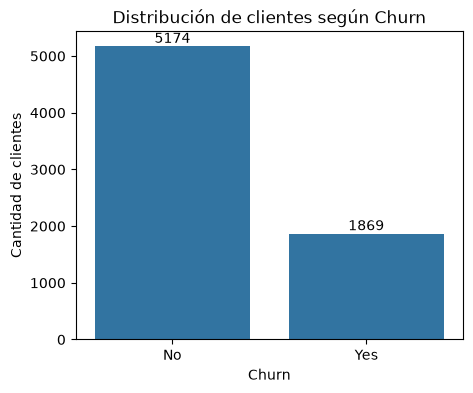

In [15]:
#Importamos las librerias de graficos
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5, 4))

ax = sns.countplot(data=df, x="Churn")
ax.bar_label(ax.containers[0])

plt.title("Distribución de clientes según Churn")
plt.xlabel("Churn")
plt.ylabel("Cantidad de clientes")

plt.show()

In [16]:
df["TotalCharges"].value_counts(dropna=False).head(10)
#Contamos los valores del TotalCharges le pones dropna False, para que no omita valores Na . y Mostramos los primeros 10

TotalCharges
20.2     11
         11
19.75     9
19.9      8
20.05     8
19.65     8
45.3      7
19.55     7
20.15     6
19.45     6
Name: count, dtype: int64

Como conclusion aqui tenemos que 11 valores son Na , asi q vamos a revisarlos

In [17]:
df["TotalCharges"].isna().sum() #Primero contaremos valores NaN 

np.int64(0)

#Como no hay valores en Nan lo que haremos es tomarlos como cadenas/string vacios

In [18]:
df["TotalCharges"].str.strip().eq("").sum() #la columna y con str.strip eliminamos vacios adelante y atras
# luego un equal para ver cadenas vacias y un sum para obtener valores

np.int64(11)

In [19]:
for column in df.select_dtypes(include="str").columns:
    print(f"\n--- {column} ---")
    print(df[column].unique())

    
#recorremos las columnas que seas strings 
#E imprimimos  el nombre de la columna, y luego los valores unicos
#solo para visualizar(opcional)


--- customerID ---
<StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str

--- gender ---
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

--- Partner ---
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

--- Dependents ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- PhoneService ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- MultipleLines ---
<StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

--- InternetService ---
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

--- OnlineSecurity ---
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

--- OnlineBackup ---
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: s

In [20]:
df[df["TotalCharges"] == " "]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [21]:
condicion = df["TotalCharges"].eq(" ")
condicion[condicion == True] # condicion[condicion] #estoy usando mascara
# listar solo los que estan en true que son " " pero sin tabla

488     True
753     True
936     True
1082    True
1340    True
3331    True
3826    True
4380    True
5218    True
6670    True
6754    True
Name: TotalCharges, dtype: bool

Ahora veremos que pasa con estos datos por que estan vacios, y hacer un buen ETL

In [22]:
df[df["TotalCharges"].str.strip() == ""][[
    "customerID",
    "tenure",
    "MonthlyCharges",
    "Contract",
    "Churn"
]]
#Igualmente pero con algunas columnas 

,customerID,tenure,MonthlyCharges,Contract,Churn
488,4472-LVYGI,0,52.55,Two year,No
753,3115-CZMZD,0,20.25,Two year,No
936,5709-LVOEQ,0,80.85,Two year,No
1082,4367-NUYAO,0,25.75,Two year,No
1340,1371-DWPAZ,0,56.05,Two year,No
3331,7644-OMVMY,0,19.85,Two year,No
3826,3213-VVOLG,0,25.35,Two year,No
4380,2520-SGTTA,0,20.00,Two year,No
5218,2923-ARZLG,0,19.70,One year,No
6670,4075-WKNIU,0,73.35,Two year,No


In [23]:
categorical_columns = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "Churn"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))
    
#tmb podemos extrar cno include (str) para variables categoricas u object


gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

DeviceProtection:
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

TechSupport:
TechSupport
No   

## Conclusiones de la auditoría de calidad

- El dataset contiene 7,043 registros y 21 variables.
- No se encontraron filas duplicadas ni `customerID` duplicados.
- Se identificaron 11 registros con `TotalCharges` vacío.
- Los 11 registros corresponden a clientes con `tenure = 0`, clientes recien añadidos, por lo que se conservarán y se tratarán posteriormente durante la preparación de los datos.
- Las variables categóricas presentan categorías consistentes y no se identificaron valores evidentemente inválidos.
- La variable objetivo `Churn` presenta 5,174 clientes que no cancelaron, no abandonaron (73.46%) y 1,869 que cancelaron , abandonaron(26.54%).
- Debido a esta distribución, el modelo no será evaluado únicamente mediante Accuracy; también se considerarán Precision, Recall, F1-score y ROC-AUC.

Siguente: Pasaremos un dataset filtrado, vamos a cambiar esos "" por valor numerico "0"

In [24]:
df["TotalCharges"].dtype

<StringDtype(storage='python', na_value=nan)>

In [25]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [26]:
df["TotalCharges"].isna().sum()

np.int64(11)

In [27]:
df[df["TotalCharges"].isna()][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [28]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [29]:
print("Valores faltantes en TotalCharges:", df["TotalCharges"].isna().sum())
print("Tipo de dato:", df["TotalCharges"].dtype)

Valores faltantes en TotalCharges: 0
Tipo de dato: float64


In [30]:
df.to_csv(
    "../data/processed/telco_churn_clean.csv",
    index=False
)

In [32]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
print("Duplicados:", df.duplicated().sum())
print("Valores faltantes totales:", df.isna().sum().sum())

Filas: 7043
Columnas: 21
Duplicados: 0
Valores faltantes totales: 0
